<a href="https://colab.research.google.com/github/hikaaru13/PCVK-GANJIL-TUGAS/blob/main/Week7_Muhammad%20Abit%20Yusuf%20Alghazaly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

2

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import Library Utama
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


3

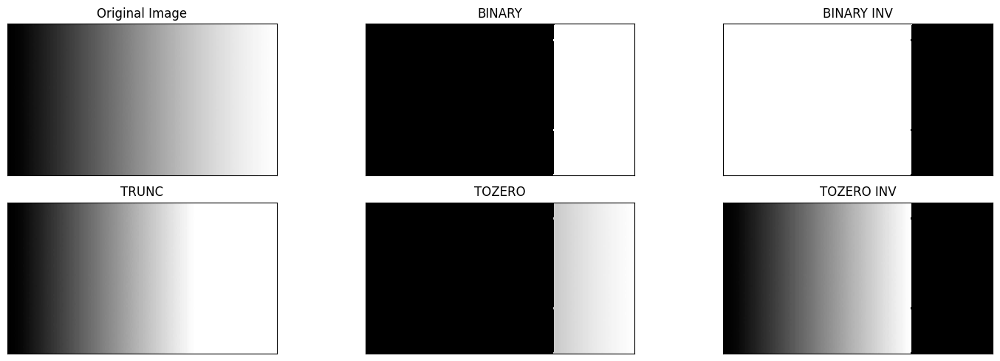

In [ ]:
# Load Citra Grayscale (Atur path sesuai direktori Anda)
img_path = '/content/drive/MyDrive/PCVK/images/gradient.jpg'
img_gray = cv.imread(img_path, 0)

thresh = 200
maxval = 255

# 1. BINARY
binary = np.where(img_gray > thresh, maxval, 0).astype(np.uint8)

# 2. BINARY_INV
binary_inv = np.where(img_gray > thresh, 0, maxval).astype(np.uint8)

# 3. TRUNC
trunc = np.where(img_gray > thresh, thresh, img_gray).astype(np.uint8)

# 4. TOZERO
tozero = np.where(img_gray > thresh, img_gray, 0).astype(np.uint8)

# 5. TOZERO_INV
tozero_inv = np.where(img_gray > thresh, 0, img_gray).astype(np.uint8)

# Visualisasi Hasil
titles = ['Original Image', 'BINARY', 'BINARY INV', 'TRUNC', 'TOZERO', 'TOZERO INV']
images = [img_gray, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

4

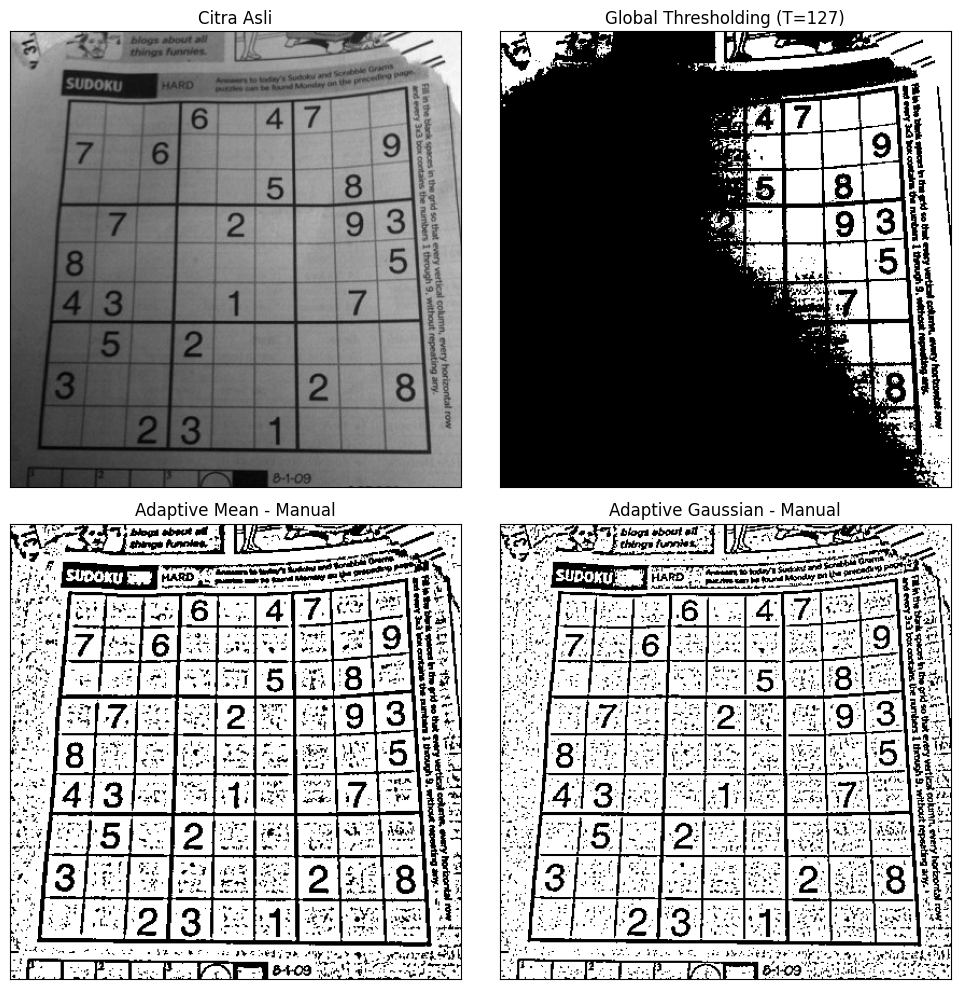

In [ ]:
# 1. Load Citra Sudoku
img_sudoku = cv.imread('/content/drive/MyDrive/PCVK/images/sudoku-original.jpg', 0)

# 2. Global Threshold Manual (T=127)
global_thresh = np.where(img_sudoku > 127, 255, 0).astype(np.uint8)

# Parameter Adaptive
block_size = 11
C = 2
sigma = 2
pad = block_size // 2

# Padding citra agar ukuran piksel tepi tidak berkurang
padded_img = np.pad(img_sudoku, pad, mode='reflect').astype(np.float32)
h, w = img_sudoku.shape

adaptive_mean = np.zeros((h, w), dtype=np.uint8)
adaptive_gaussian = np.zeros((h, w), dtype=np.uint8)

# Kernel Gaussian 11x11 manual
x, y = np.mgrid[-pad:pad+1, -pad:pad+1]
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
gaussian_kernel /= gaussian_kernel.sum()

# Iterasi Local Window
for i in range(h):
    for j in range(w):
        window = padded_img[i:i+block_size, j:j+block_size]

        # Mean
        mean_val = np.mean(window)
        T_mean = mean_val - C
        adaptive_mean[i, j] = 255 if img_sudoku[i, j] > T_mean else 0

        # Gaussian
        gauss_val = np.sum(window * gaussian_kernel)
        T_gauss = gauss_val - C
        adaptive_gaussian[i, j] = 255 if img_sudoku[i, j] > T_gauss else 0

# Visualisasi
titles = ['Citra Asli', 'Global Thresholding (T=127)',
          'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [img_sudoku, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(10, 10))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow(images[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

5

Fungsi Kode: Mengelompokkan area citra berdasarkan prinsip penjalaran wilayah (region growing), yaitu mengumpulkan piksel-piksel bertetangga yang memiliki kesamaan warna atau intensitas dari satu titik acuan (seed).
Penjelasan Baris Kunci:

-seed_point=(121, 63): Titik koordinat awal (baris, kolom) tempat algoritma mulai memeriksa warna piksel.

-tolerance=20: Batas toleransi perbedaan intensitas. Piksel tetangga akan digabungkan ke dalam kelompok jika selisih warnanya tidak lebih dari $\pm 20$ dari piksel seed.

-connectivity=1: Memeriksa 4 tetangga terdekat (atas, bawah, kiri, kanan).

-Pengaruh Nilai Toleransi ($T$): Jika $T=5$, area yang terpilih terlalu kecil (under-segmentation). Jika $T=20$, pas untuk mengambil 1 keping koin. Jika $T=60$, penjalaran warna bocor ke luar koin dan menutupi latar belakang (over-segmentation).

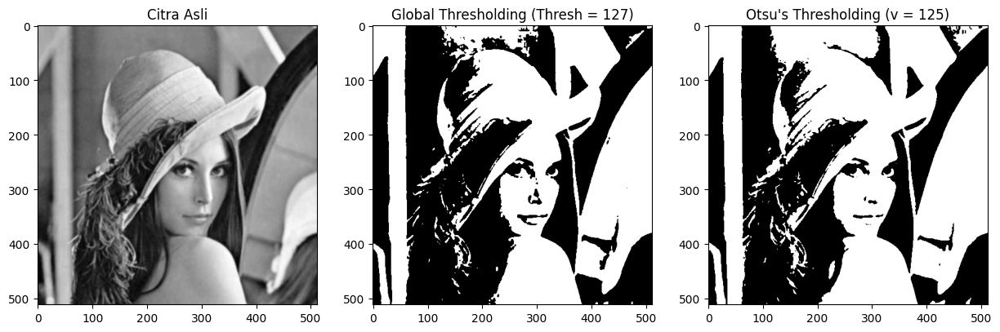

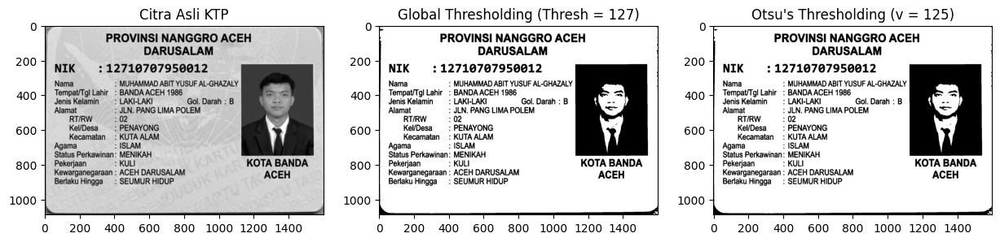

In [ ]:
# Implementasi Otsu Manual
def otsu_manual(gray_img):
    pixel_number = gray_img.shape[0] * gray_img.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray_img, np.arange(0, 257))

    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)

    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])

        if pcb == 0 or pcf == 0:
            continue

        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)

        # Calculate Between-Class Variance
        value = Wb * Wf * ((mub - muf) ** 2)

        if value > final_value:
            final_thresh = t
            final_value = value

    final_img = np.zeros_like(gray_img)
    final_img[gray_img > final_thresh] = 255
    return final_img, final_thresh

# Testing pada Citra Lena
img_lena = cv.imread('/content/drive/MyDrive/PCVK/images/lena_lc.jpg', 0)
blur_lena = cv.GaussianBlur(img_lena, (5, 5), 0)
thresh_global = 127

th_global_lena = np.where(blur_lena > thresh_global, 255, 0).astype(np.uint8)
otsu_bin_lena, otsu_val_lena = otsu_manual(blur_lena)

# Visualisasi Lena
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(blur_lena, 'gray')
plt.title('Citra Asli')

plt.subplot(1, 3, 2)
plt.imshow(th_global_lena, 'gray')
plt.title(f'Global Thresholding (Thresh = {thresh_global})')

plt.subplot(1, 3, 3)
plt.imshow(otsu_bin_lena, 'gray')
plt.title(f"Otsu's Thresholding (v = {otsu_val_lena})")
plt.show()

# Testing pada Citra KTP
img_ktp = cv.imread('/content/drive/MyDrive/PCVK/tugas kelompok/ktp abit.jpg', 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

th_global_ktp = np.where(blur_ktp > thresh_global, 255, 0).astype(np.uint8)
otsu_bin_ktp, otsu_val_ktp = otsu_manual(blur_ktp)

# Visualisasi KTP
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(blur_ktp, 'gray')
plt.title('Citra Asli KTP')

plt.subplot(1, 3, 2)
plt.imshow(th_global_ktp, 'gray')
plt.title(f'Global Thresholding (Thresh = {thresh_global})')

plt.subplot(1, 3, 3)
plt.imshow(otsu_bin_ktp, 'gray')
plt.title(f"Otsu's Thresholding (v = {otsu_val_ktp})")
plt.show()

6a

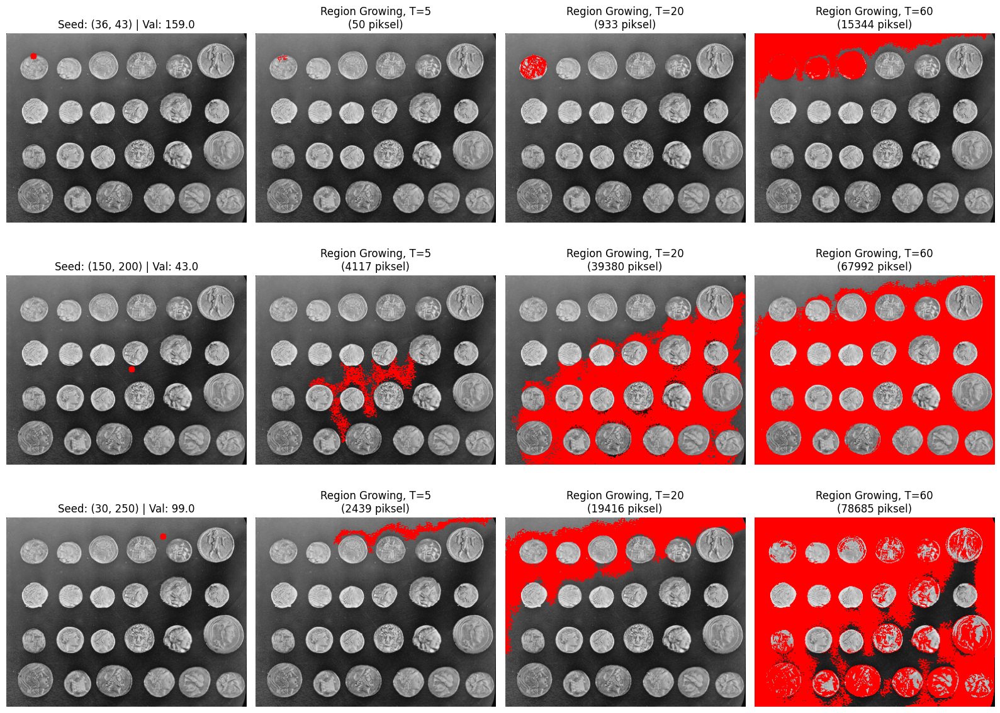

In [ ]:
from skimage import data

coins = data.coins()
seeds = [(36, 43), (150, 200), (30, 250)] # Seed 1: Koin, Seed 2: Latar, Seed 3: Tepi
thresholds = [5, 20, 60]

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row_idx, seed in enumerate(seeds):
    seed_val = coins[seed[0], seed[1]]

    # Visualisasi Citra Asli dengan titik seed
    seed_img = cv.cvtColor(coins, cv.COLOR_GRAY2RGB)
    cv.circle(seed_img, (seed[1], seed[0]), 5, (255, 0, 0), -1)

    axes[row_idx, 0].imshow(seed_img)
    axes[row_idx, 0].set_title(f"Seed: {seed} | Val: {seed_val:.1f}")

    for col_idx, T in enumerate(thresholds):
        # Region Growing menggunakan skimage.segmentation.flood
        mask = flood(coins, seed, tolerance=T)
        num_pixels = np.sum(mask)

        # Tampilkan region berwarna merah di atas citra asli
        res_img = cv.cvtColor(coins, cv.COLOR_GRAY2RGB)
        res_img[mask] = [255, 0, 0]

        axes[row_idx, col_idx + 1].imshow(res_img)
        axes[row_idx, col_idx + 1].set_title(f"Region Growing, T={T}\n({num_pixels} piksel)")

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

6b

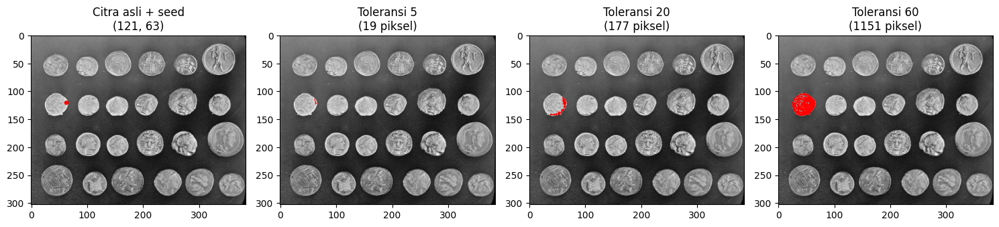

In [ ]:
gray = data.coins()
seed = (121, 63)

plt.figure(figsize=(15, 4))

# Visualisasi Seed
img_seed = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
cv.circle(img_seed, (seed[1], seed[0]), 4, (255, 0, 0), -1)
plt.subplot(1, 4, 1)
plt.imshow(img_seed)
plt.title(f"Citra asli + seed\n{seed}")

for idx, tol in enumerate([5, 20, 60]):
    region = flood(gray, seed_point=seed, tolerance=tol, connectivity=1)
    res = cv.cvtColor(gray, cv.COLOR_GRAY2RGB)
    res[region] = [255, 0, 0]

    plt.subplot(1, 4, idx + 2)
    plt.imshow(res)
    plt.title(f"Toleransi {tol}\n({np.sum(region)} piksel)")

plt.tight_layout()
plt.show()

7

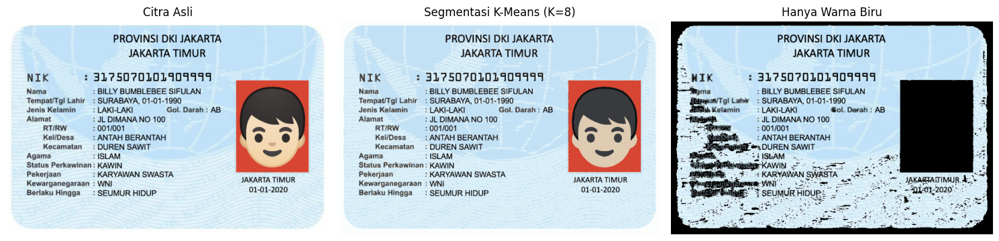

In [ ]:
# 1. Load Citra KTP dan konversi ruang warna
ktp_bgr = cv.imread('/content/drive/MyDrive/PCVK/images/ktp1.jpg')
ktp_rgb = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2RGB)

# 2. K-Means Clustering (K=8)
Z = ktp_rgb.reshape((-1, 3))
Z = np.float32(Z)

criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 8
ret, label, center = cv.kmeans(Z, K, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)

center = np.uint8(center)
res = center[label.flatten()]
kmeans_img = res.reshape((ktp_rgb.shape))

# 3. Filtering Spesifik Warna Biru menggunakan ruang HSV
ktp_hsv = cv.cvtColor(ktp_rgb, cv.COLOR_RGB2HSV)

# Rentang HSV warna biru KTP
lower_blue = np.array([85, 25, 40])
upper_blue = np.array([130, 255, 255])

blue_mask = cv.inRange(ktp_hsv, lower_blue, upper_blue)

# Terapkan Masking pada hasil citra KTP
blue_only = cv.bitwise_and(ktp_rgb, ktp_rgb, mask=blue_mask)

# Visualisasi Hasil
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(ktp_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(kmeans_img)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(blue_only)
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

D2. TUGAS KELOMPOK (OCR KTP)

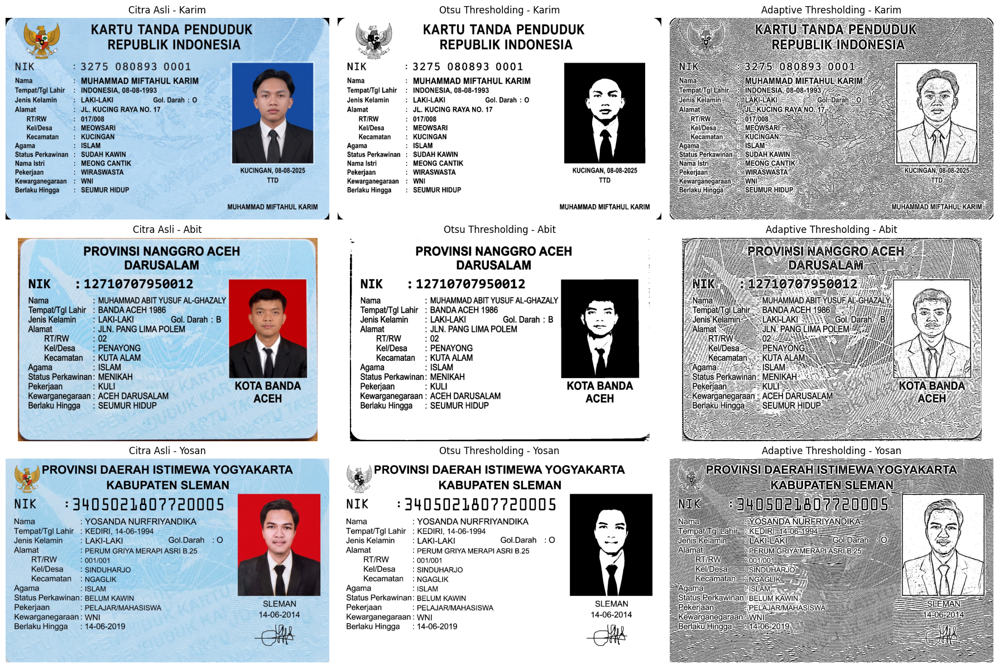

In [ ]:
# Daftar path citra sesuai dengan yang Anda berikan
image_paths = [
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp karim.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp abit.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp yossan.jpg'
]

# Nama anggota untuk penamaan judul plot
names = ['Karim', 'Abit', 'Yosan']

# Siapkan figure dengan ukuran grid 3 baris dan 3 kolom
plt.figure(figsize=(18, 12))

for i, path in enumerate(image_paths):
    # 1a. Membaca citra berwarna asli
    img_color = cv.imread(path)

    if img_color is not None:
        # Konversi BGR ke RGB agar warna sesuai di Matplotlib
        img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

        # Konversi ke Grayscale untuk metode thresholding
        img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

        # 1b. Citra hasil segmentasi menggunakan Otsu Thresholding
        ret, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

        # 1c. Citra hasil segmentasi menggunakan Adaptive Thresholding
        img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

        # Plot Citra Berwarna Asli
        plt.subplot(3, 3, i*3 + 1)
        plt.imshow(img_rgb)
        plt.title(f'Citra Asli - {names[i]}')
        plt.axis('off')

        # Plot Citra Otsu
        plt.subplot(3, 3, i*3 + 2)
        plt.imshow(img_otsu, cmap='gray')
        plt.title(f'Otsu Thresholding - {names[i]}')
        plt.axis('off')

        # Plot Citra Adaptive
        plt.subplot(3, 3, i*3 + 3)
        plt.imshow(img_adaptive, cmap='gray')
        plt.title(f'Adaptive Thresholding - {names[i]}')
        plt.axis('off')
    else:
        print(f"Peringatan: Gambar tidak ditemukan di path '{path}'")

plt.tight_layout()
plt.show()

In [ ]:
# Pasang tesseract-ocr dan data bahasa Indonesia (ind)
!apt-get update
!apt-get install -y tesseract-ocr tesseract-ocr-ind
!pip install pytesseract

Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
tesseract-ocr-ind is already the newest version (1:4.1.0-2).
0 upgraded, 0 newly installed, 0 to remove and 3

In [ ]:
# Daftar path citra asli
image_paths = [
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp karim.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp abit.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp yossan.jpg'
]

names = ['Karim', 'Abit', 'Yosan']

# Pengaturan konsisten: bahasa Indonesia dan psm 6
custom_config = r'--oem 3 --psm 6'

for i, path in enumerate(image_paths):
    # Membaca citra
    img_color = cv.imread(path)

    if img_color is not None:
        # Konversi BGR ke RGB (Tesseract membaca format RGB lebih akurat)
        img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

        print(f"==================================================")
        print(f" HASIL PEMBACAAN TEKS OCR - KTP {names[i].upper()} (CITRA ASLI)")
        print(f"==================================================")

        # Ekstraksi teks pada citra berwarna asli
        text_color = pytesseract.image_to_string(img_rgb, lang='ind', config=custom_config)
        print(text_color if text_color.strip() else "(Tidak ada teks terbaca)")
        print("\n")
    else:
        print(f"Peringatan: Gambar tidak ditemukan di path '{path}'")

 HASIL PEMBACAAN TEKS OCR - KTP KARIM (CITRA ASLI)
£
k KARTU TANDA PENDUDUK
Se. REPUBLIK INDONESIA
KE

NIK :3275 080893 0001
Nama : MUHAMMAD MIFTAHUL KARIM
Tempat/Tgl Lahir : INDONESIA, 08-08-1993 2.
Jenis Kelamin » LAKI-LAKI Gol. Darah : O (NP 1
Alamat » JL. KUCING RAYA NO. 17 | y £

RT/RW : 017/008 -

Kel/Desa : MEOWSARI

Kecamatan : KUCINGAN
Agama : ISLAM |
Status Perkawinan : SUDAH KAWIN
Nama Istri : MEONG CANTIK
Pekerjaan : WIRASWASTA KUCINGAN, 08-08-2025
Kewarganegaraan : WNI TTD
Berlaku Hingga : SEUMUR HIDUP

MUHAMMAD MIFTAHUL KARIM
N ”



 HASIL PEMBACAAN TEKS OCR - KTP ABIT (CITRA ASLI)
PROVINSI NANGGRO ACEH
DARUSALAM
NIK : 12710707950012
Nama : MUHAMMAD ABIT YUSUF AL-GHAZALY
Tempat/Tgl Lahir : BANDA ACEH 1986 1 5
Jenis Kelamin : LAKI-LAKI Gol. Darah : B (2
Alamat : JLN. PANG LIMA POLEM |
RT/RW :02 |
Kel/Desa : PENAYONG |
Kecamatan : KUTA ALAM
Agama : ISLAM
Status Perkawinan: MENIKAH
Pekerjaan : KULI KOTA BANDA
Kewarganegaraan : ACEH DARUSALAM ACEH
Berlaku Hingga — : SEUMUR HI

--- Rata-rata Confidence KTP Karim ---
Berwarna Asli : 90.84%
Otsu          : 91.41%
Adaptive      : 76.95%

--- Rata-rata Confidence KTP Abit ---
Berwarna Asli : 91.73%
Otsu          : 91.31%
Adaptive      : 81.14%

--- Rata-rata Confidence KTP Yosan ---
Berwarna Asli : 90.40%
Otsu          : 91.48%
Adaptive      : 78.83%



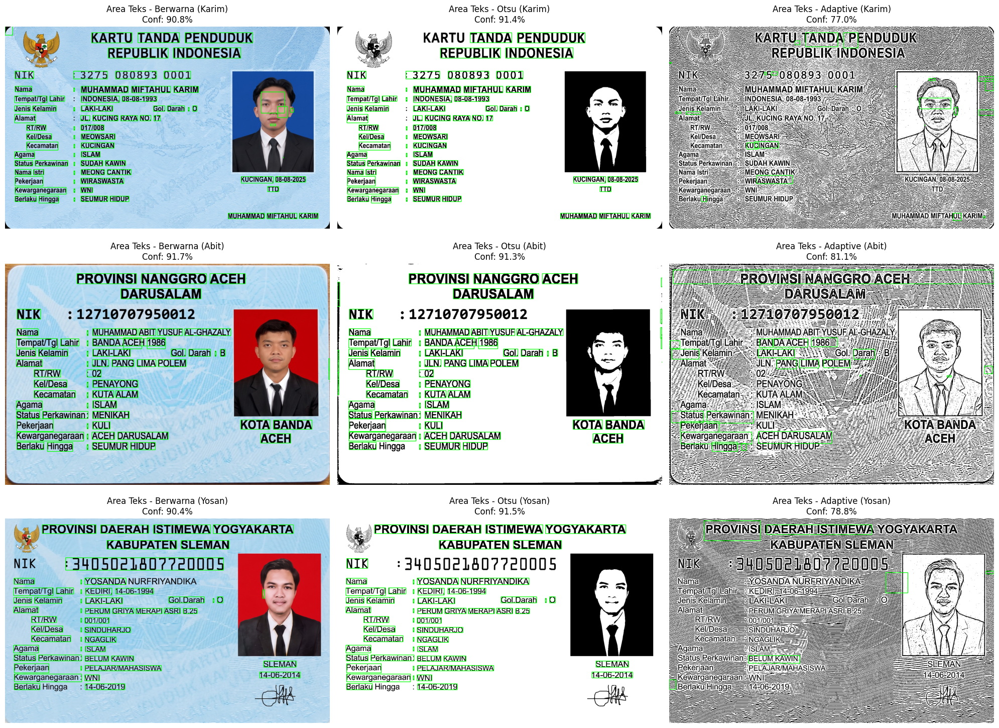

In [ ]:
# Daftar path citra
image_paths = [
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp karim.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp abit.jpg',
    '/content/drive/MyDrive/PCVK/tugas kelompok/ktp yossan.jpg'
]

names = ['Karim', 'Abit', 'Yosan']

# Pengaturan konsisten: bahasa Indonesia dan psm 6
custom_config = r'--oem 3 --psm 6'
conf_threshold = 60  # Batas confidence > 60

def draw_text_boxes(image, is_gray=False):
    """
    Fungsi untuk menjalankan OCR, menggambar kotak hijau,
    dan menghitung rata-rata confidence.
    """
    if is_gray:
        img_for_ocr = image
        img_canvas = cv.cvtColor(image, cv.COLOR_GRAY2RGB)
    else:
        img_for_ocr = cv.cvtColor(image, cv.COLOR_BGR2RGB)
        img_canvas = img_for_ocr.copy()

    d = pytesseract.image_to_data(img_for_ocr, lang='ind', config=custom_config, output_type=Output.DICT)
    n_boxes = len(d['text'])

    total_conf = 0
    valid_words = 0

    for i in range(n_boxes):
        conf = int(d['conf'][i])

        if conf > conf_threshold:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            cv.rectangle(img_canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)

            # Tambahkan perhitungan rata-rata
            total_conf += conf
            valid_words += 1

    # Hitung rata-rata confidence
    avg_conf = total_conf / valid_words if valid_words > 0 else 0
    return img_canvas, avg_conf

plt.figure(figsize=(20, 15))

for i, path in enumerate(image_paths):
    img_color = cv.imread(path)

    if img_color is not None:
        img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)
        ret, img_otsu = cv.threshold(img_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
        img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

        # Ambil gambar berkotak sekaligus nilai rata-rata confidence-nya
        box_color, conf_color = draw_text_boxes(img_color, is_gray=False)
        box_otsu, conf_otsu = draw_text_boxes(img_otsu, is_gray=True)
        box_adaptive, conf_adaptive = draw_text_boxes(img_adaptive, is_gray=True)

        # Cetak nilai rata-rata confidence ke layar untuk diisi ke tabel
        print(f"--- Rata-rata Confidence KTP {names[i]} ---")
        print(f"Berwarna Asli : {conf_color:.2f}%")
        print(f"Otsu          : {conf_otsu:.2f}%")
        print(f"Adaptive      : {conf_adaptive:.2f}%\n")

        plt.subplot(3, 3, i*3 + 1)
        plt.imshow(box_color)
        plt.title(f'Area Teks - Berwarna ({names[i]})\nConf: {conf_color:.1f}%')
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 2)
        plt.imshow(box_otsu)
        plt.title(f'Area Teks - Otsu ({names[i]})\nConf: {conf_otsu:.1f}%')
        plt.axis('off')

        plt.subplot(3, 3, i*3 + 3)
        plt.imshow(box_adaptive)
        plt.title(f'Area Teks - Adaptive ({names[i]})\nConf: {conf_adaptive:.1f}%')
        plt.axis('off')
    else:
        print(f"Peringatan: Gambar tidak ditemukan di path '{path}'")

plt.tight_layout()
plt.show()